# OliveSmart OLV-6 — comparaison scientifique de cinq algorithmes

## Introduction et objectifs

Ce notebook documente l'Étape 1 du projet **OliveSmart OLV-6 : détection temporelle des oliviers dépérissants ou morts**. Il compare sur les mêmes arbres OQDS :

1. un seuil de variation d'intensité ;
2. un CUSUM unilatéral ;
3. une Isolation Forest ;
4. un Siamese CNN sur deux observations RGB ;
5. un Temporal Convolutional Network (TCN) sur trois observations annuelles.

La cible `is.infect=True` désigne un arbre présent en 2019 puis absent en 2020/2021, interprété par les auteurs comme un retrait après infection probable. Elle ne constitue pas un diagnostic PCR individuel. Les rasters locaux nommés « NDVI » sont des rendus RGBA 8 bits sans calibration : les variables dérivées sont donc appelées **intensités**, jamais NDVI physique.

Les traitements volumineux restent organisés dans quatre scripts auditables : [audit](scripts/audit_datasets.py), [préparation](scripts/prepare_oqds.py), [entraînement/évaluation](scripts/train_evaluate.py) et [expériences complémentaires/rapport](scripts/complementary_report.py). Les principaux blocs scientifiques sont néanmoins reproduits directement ci-dessous.

## 0 — Deux modes d'exécution

- `consultation` — mode par défaut : recharge les artefacts déjà calculés, vérifie leur cohérence et recrée seulement les tableaux/visualisations légères du notebook. **Aucun modèle n'est réentraîné.**
- `reproduction_complete` — repart des données brutes et exécute successivement audit, préparation, optimisation des cinq modèles, Test final et expériences complémentaires. Il faut également positionner `CONFIRMER_REENTRAINEMENT_COUTEUX=True` afin d'éviter un lancement accidentel.

La reproduction complète remplace les artefacts calculés portant les mêmes noms, mais ne modifie jamais les datasets bruts.

In [1]:
from pathlib import Path
import json, os, random, subprocess, sys, time
import joblib, matplotlib.pyplot as plt, numpy as np, pandas as pd
import geopandas as gpd, rasterio, sklearn, torch
from IPython.display import display, Markdown, Image
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, Dataset

ROOT = Path.cwd().resolve()
assert ROOT.name == 'Project-JEE_DL', f'Ouvrir depuis la racine du projet : {ROOT}'
DATA, PROC = ROOT/'data', ROOT/'data/processed'
RESULTS, FIGURES, MODELS = ROOT/'outputs/results', ROOT/'outputs/figures', ROOT/'outputs/models'
SEED = 20261106
PATCH = 16
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

EXECUTION_MODE = 'consultation'  # ou 'reproduction_complete'
CONFIRMER_REENTRAINEMENT_COUTEUX = False

print({'mode': EXECUTION_MODE, 'python': sys.version.split()[0], 'torch': torch.__version__,
       'device': str(DEVICE), 'sklearn': sklearn.__version__, 'rasterio': rasterio.__version__})

{'mode': 'consultation', 'python': '3.12.13', 'torch': '2.15.0+cpu', 'device': 'cpu', 'sklearn': '1.9.1', 'rasterio': '1.5.2'}


In [2]:
def executer_script(nom):
    print(f'Exécution de scripts/{nom} ...')
    subprocess.run([sys.executable, str(ROOT/'scripts'/nom)], cwd=ROOT, check=True)

if EXECUTION_MODE not in {'consultation', 'reproduction_complete'}:
    raise ValueError('Mode inconnu')
if EXECUTION_MODE == 'reproduction_complete':
    if not CONFIRMER_REENTRAINEMENT_COUTEUX:
        raise RuntimeError('Positionner CONFIRMER_REENTRAINEMENT_COUTEUX=True pour autoriser le recalcul complet.')
    for script in ['audit_datasets.py', 'prepare_oqds.py', 'train_evaluate.py', 'complementary_report.py']:
        executer_script(script)
else:
    print('Consultation : les résultats sauvegardés sont chargés sans réentraînement.')

Consultation : les résultats sauvegardés sont chargés sans réentraînement.


## 1 — Exploration des quatre datasets

L'audit parcourt réellement les fichiers, lit les métadonnées géospatiales, les schémas tabulaires, les dimensions des cubes/images et les annotations. Le CSV d'inventaire est exhaustif ; les JSON détaillent chaque source.

In [3]:
audit_path = ROOT/'outputs/results/PHASE_A_AUDIT.md'
inventory_path = ROOT/'outputs/results/dataset_inventory.csv'
assert audit_path.exists() and inventory_path.exists(), 'Exécuter audit_datasets.py'
display(Markdown(audit_path.read_text(encoding='utf-8')))
inventory = pd.read_csv(inventory_path)
inventory_summary = (inventory.groupby(['dataset','role'], dropna=False)
                     .agg(fichiers=('path','size'), taille_Mio=('size_bytes', lambda x: x.sum()/2**20))
                     .reset_index())
display(inventory_summary)

# Audit scientifique des sources OLV-6

Audit généré depuis les fichiers présents localement, sans modification des données brutes.

## OQDS Insight

- 6 GeoTIFF et 1 shapefile détectés.
- Années déduites des noms : ['2019', '2020', '2021'].
- Métadonnées détaillées : `outputs/results/oqds_metadata.json`.

## NEON Tree Crowns

- 1 GeoPackage, 41,738 entités.
- Schéma, identifiants et dates candidates : `outputs/results/neon_metadata.json`.

## Olive Hyperspectral Stress

- 1 classeur et 8 cubes TIFF.
- Dimensions des cubes : [(50, 50, 138), (50, 50, 138), (50, 50, 138), (50, 50, 138), (50, 50, 138), (50, 50, 138), (50, 50, 138), (50, 50, 138)].
- Classes, bandes, valeurs manquantes et tags : `outputs/results/hyperspectral_metadata.json`.

## OliveTreeCrownsDb

- 5,844 images, 5,084 XML Pascal VOC, 5,084 fichiers texte.
- 33,479 boîtes VOC ; classes : {'0': 33479}.
- Résolutions/modes : {(5472, 3648, 'RGB'): 46, (1824, 1216, 'RGB'): 414, (912, 608, 'RGB'): 1656, (608, 405, 'RGB'): 3726, (829, 701, 'RGBA'): 1, (855, 701, 'RGBA'): 1}.
- Indices temporels explicites dans les noms : {}.
- Audit détaillé : `outputs/results/crownsdb_metadata.json`.

## Conclusion d'aptitude initiale

- **OQDS** est la seule source candidate à un benchmark temporel commun si les mêmes points sont couverts en 2019–2021 et si l'étiquette vectorielle représente bien l'état cible.
- **NEON** peut documenter les observations répétées et la transférabilité structurelle, mais ne doit pas être fusionné avec les classes d'oliviers sans cible compatible.
- **Hyperspectral** permet une expérience complémentaire de classification de stress spectral, distincte du benchmark temporel OQDS.
- **CrownsDb** permet une expérience de contrôle qualité/détection de couronnes, mais l'absence de suivi temporel explicite interdit de le présenter comme preuve de détection du dépérissement.

Inventaire exhaustif : 16,033 fichiers dans `outputs/results/dataset_inventory.csv`.


,dataset,role,fichiers,taille_Mio
0,CrownsDb,auxiliary,4,32.741459
1,CrownsDb,image,5844,1947.218246
2,CrownsDb,voc_annotation,5084,3.894135
3,CrownsDb,yolo_annotation,5084,178.226125
4,Hyperspectral,spectral_cube,8,5.271851
5,Hyperspectral,spreadsheet,1,1.876379
6,NEON,geopackage,1,26.230469
7,OQDS,raster,6,2817.594343
8,OQDS,vector,1,2.058514


In [4]:
oqds_meta = json.loads((ROOT/'outputs/results/oqds_metadata.json').read_text(encoding='utf-8'))
neon_meta = json.loads((ROOT/'outputs/results/neon_metadata.json').read_text(encoding='utf-8'))
hs_meta = json.loads((ROOT/'outputs/results/hyperspectral_metadata.json').read_text(encoding='utf-8'))
crowns_meta = json.loads((ROOT/'outputs/results/crownsdb_metadata.json').read_text(encoding='utf-8'))

display(pd.DataFrame(oqds_meta['rasters'])[['name','width','height','bands','dtype','crs','resolution']])
print('OQDS vectoriel :', oqds_meta['vectors'][0]['rows'], 'arbres ; colonnes', oqds_meta['vectors'][0]['columns'])
print('NEON :', neon_meta[0]['rows'], 'couronnes ; années candidates', neon_meta[0]['date_values'])
print('Hyperspectral :', [(x['sheet'], x['rows']) for x in hs_meta['excel']], '; cubes =', len(hs_meta['cubes']))
print('CrownsDb :', crowns_meta['files'], 'fichiers ;', crowns_meta['voc_boxes'], 'boîtes VOC')

,name,width,height,bands,dtype,crs,resolution
0,2019_WV2_NDVI.tif,14462,9727,4,"uint8,uint8,uint8,uint8",EPSG:32633,"[0.5, 0.5]"
1,2019_WV2_RGB.tif,14462,9727,3,"uint8,uint8,uint8",EPSG:32633,"[0.5, 0.5]"
2,2020_WV2_NDVI.tif,14462,9727,4,"uint8,uint8,uint8,uint8",EPSG:32633,"[0.5, 0.5]"
3,2020_WV2_RGB.tif,14462,9727,3,"uint8,uint8,uint8",EPSG:32633,"[0.5, 0.5]"
4,2021_WV2_NDVI.tif,14462,9727,4,"uint8,uint8,uint8,uint8",EPSG:32633,"[0.5, 0.5]"
5,2021_WV2_RGB.tif,14462,9727,3,"uint8,uint8,uint8",EPSG:32633,"[0.5, 0.5]"


OQDS vectoriel : 77086 arbres ; colonnes ['fid', 'year', 'is.infect', 'geometry']
NEON : 41738 couronnes ; années candidates {'anno_year': ['2019.0', '2020.0', '2018.0', '2022.0', '2024.0', '2021.0', '2023.0'], 'detection_year': ['2021.0', '2019.0', '2022.0', '2018.0', '2017.0', '2020.0']}
Hyperspectral : [('hs_and_ground_truth', 76), ('Φύλλο1', 307), ('Sheet1', 76)] ; cubes = 8
CrownsDb : 16016 fichiers ; 33479 boîtes VOC


### Interprétation de l'audit

OQDS est la seule source réunissant trois dates co-enregistrées et une cible compatible avec le benchmark commun. NEON concerne d'autres taxons ; le fichier présent ne permet finalement pas un suivi multi-annuel par individu. Le classeur hyperspectral porte une cible de stress distincte. CrownsDb documente les couronnes mais ne possède ni date sanitaire ni classe de dépérissement. Ces sources ne sont donc pas fusionnées artificiellement.

## 2 — Nettoyage, contrôle qualité et visualisation des données

,observations_exclues
mostly_black_rgb,4959
low_alpha_coverage,59
outside_or_patch_border,8


,valid,target,effectif
0,False,0,4928
1,False,1,98
2,True,0,69887
3,True,1,2069


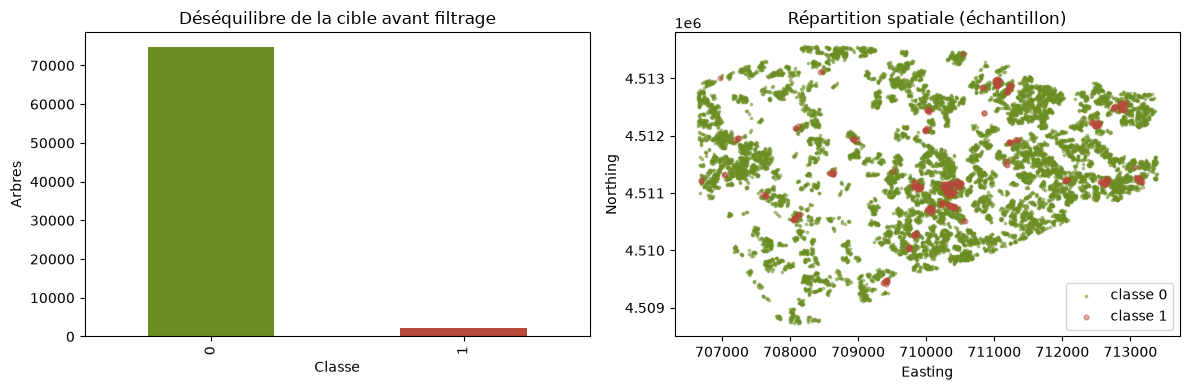

In [5]:
qc = pd.read_csv(ROOT/'data/processed/oqds_qc_all.csv')
features = pd.read_csv(ROOT/'data/processed/oqds_features_splits.csv', dtype={'tree_id': str})
prep = json.loads((ROOT/'outputs/results/preparation_summary.json').read_text(encoding='utf-8'))
display(pd.Series(prep['invalid_counts'], name='observations_exclues').to_frame())
display(qc.groupby(['valid','target']).size().rename('effectif').reset_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
qc.target.value_counts().sort_index().plot.bar(ax=axes[0], color=['#6b8e23','#b84a3a'])
axes[0].set(title='Déséquilibre de la cible avant filtrage', xlabel='Classe', ylabel='Arbres')
sample = features.sample(min(12000, len(features)), random_state=SEED)
for label, color in [(0, '#6b8e23'), (1, '#b84a3a')]:
    z = sample[sample.target == label]
    axes[1].scatter(z.x, z.y, s=3 if label == 0 else 12, alpha=.45, color=color, label=f'classe {label}')
axes[1].set(title='Répartition spatiale (échantillon)', xlabel='Easting', ylabel='Northing'); axes[1].legend()
plt.tight_layout(); plt.show()

Règles appliquées avant tout split : suppression des coordonnées dupliquées sans contradiction de label, exclusion des centres hors emprise/bordure, couverture alpha minimale de 80 %, et exclusion des patches RGB noirs à plus de 80 %. Les données brutes ne sont jamais modifiées.

## 3 — Prétraitement et extraction des caractéristiques

In [6]:
def padded_indices(rows: np.ndarray, cols: np.ndarray, h: int, w: int, radius: int = 2):
    offsets = np.arange(-radius, radius + 1)
    rr = np.clip(rows[:, None, None] + offsets[None, :, None], 0, h - 1)
    cc = np.clip(cols[:, None, None] + offsets[None, None, :], 0, w - 1)
    return rr, cc


def extract_patch_array(path: Path, rows: np.ndarray, cols: np.ndarray, valid: np.ndarray, out_path: Path) -> dict:
    """Charge un seul grand raster à la fois et écrit les petits patches dans un memmap."""
    n = len(rows)
    patches = np.lib.format.open_memmap(out_path, mode="w+", dtype=np.uint8, shape=(n, 3, PATCH, PATCH))
    patches[:] = 0
    with rasterio.open(path) as src:
        rgb = src.read([1, 2, 3])
        half = PATCH // 2
        black_ratios = np.ones(n, dtype=np.float32)
        for i in np.flatnonzero(valid):
            r, c = int(rows[i]), int(cols[i])
            r0, r1, c0, c1 = r - half, r + half, c - half, c + half
            if r0 < 0 or c0 < 0 or r1 > src.height or c1 > src.width:
                valid[i] = False
                continue
            patch = rgb[:, r0:r1, c0:c1]
            patches[i] = patch
            black_ratios[i] = float(np.mean(np.all(patch == 0, axis=0)))
        del rgb
    patches.flush()
    return {"black_ratio": black_ratios}

Le script lit un grand raster à la fois afin de limiter la mémoire. Pour chaque arbre, il calcule moyenne, écart-type, percentiles 10/90 de l'intensité sur une fenêtre 5×5, variations absolues/relatives entre années, et deux patches RGB 16×16 (2019 et 2021). Les patches sont stockés en `uint8` dans `data/processed/` et ne sont convertis/normalisés qu'au chargement.

Caractéristiques numériques: 18


,variable
0,intensity_mean_2019
1,intensity_std_2019
2,intensity_p10_2019
3,intensity_p90_2019
4,intensity_mean_2020
5,intensity_std_2020
6,intensity_p10_2020
7,intensity_p90_2020
8,intensity_mean_2021
9,intensity_std_2021


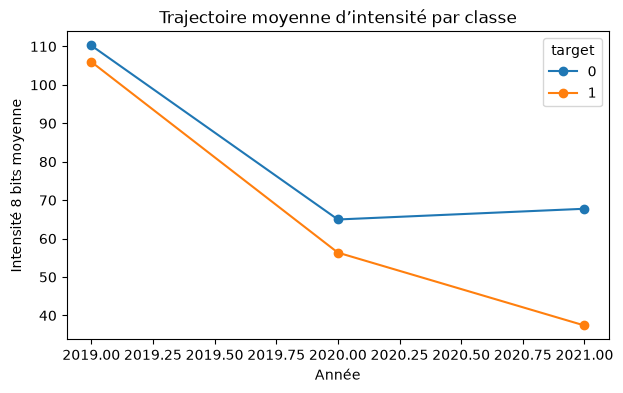

In [7]:
feature_cols = [c for c in features.columns if c.startswith(('intensity_', 'delta_mean_', 'relative_delta_'))]
print('Caractéristiques numériques:', len(feature_cols)); display(pd.Series(feature_cols, name='variable').to_frame())

means = features.groupby('target')[[f'intensity_mean_{y}' for y in (2019,2020,2021)]].mean().T
means.index = [2019, 2020, 2021]
means.plot(marker='o', figsize=(7,4), title='Trajectoire moyenne d’intensité par classe')
plt.xlabel('Année'); plt.ylabel('Intensité 8 bits moyenne'); plt.show()

## 4 — Découpage Train / Validation / Test

In [8]:
split_table = features.groupby('split').target.agg(effectif='size', positifs='sum', prevalence='mean')
split_table['blocs'] = features.groupby('split').spatial_block.nunique()
display(split_table)
assert features.groupby('tree_id').split.nunique().max() == 1
assert features.groupby('spatial_block').split.nunique().max() == 1
assert all(features.groupby('split').target.nunique() == 2)
print('Contrôle réussi : aucun arbre ni bloc spatial partagé entre partitions.')

,effectif,positifs,prevalence,blocs
split,,,,
test,10205,237,0.023224,52
train,51425,1541,0.029966,258
val,10326,291,0.028181,53


Contrôle réussi : aucun arbre ni bloc spatial partagé entre partitions.


Les blocs spatiaux mesurent 250 m. Sept folds groupés et stratifiés sont construits avec une graine fixe ; le fold Test est gelé. Un fold Validation à prévalence comparable est choisi **avant entraînement**, sans consulter les performances Test. Train sert à ajuster modèles et normalisations, Validation aux hyperparamètres/seuils, Test à l'évaluation finale unique.

## 5 — Métriques et sélection du seuil sur Validation

In [9]:
def metrics(y: np.ndarray, score: np.ndarray, threshold: float) -> dict:
    pred = (score >= threshold).astype(np.uint8)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, score), "pr_auc": average_precision_score(y, score),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp), "threshold": float(threshold),
    }


def best_threshold(y: np.ndarray, score: np.ndarray) -> float:
    precision, recall, thresholds = precision_recall_curve(y, score)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[int(np.nanargmax(f1))]) if len(thresholds) else 0.5

La PR-AUC est le critère principal de sélection car les positifs ne représentent que 2–3 % des arbres. Accuracy, précision, rappel, F1, ROC-AUC et matrice de confusion complètent l'analyse. Le seuil maximisant F1 est calculé sur Validation uniquement.

## 6 — Baseline par seuil de variation

In [10]:
def baseline_score(frame: pd.DataFrame, mode: str) -> np.ndarray:
    a, b, c = (frame[f"intensity_mean_{y}"].to_numpy() for y in (2019, 2020, 2021))
    if mode == "decline_2019_2021":
        return a - c
    if mode == "max_annual_decline":
        return np.maximum(a - b, b - c)
    if mode == "relative_decline":
        return (a - c) / (np.abs(a) + 1.0)
    raise KeyError(mode)


def cusum_score(frame: pd.DataFrame, relative: bool, k: float) -> np.ndarray:
    x = frame[[f"intensity_mean_{y}" for y in (2019, 2020, 2021)]].to_numpy(float)
    diffs = x[:, :-1] - x[:, 1:]
    if relative:
        diffs = diffs / (np.abs(x[:, :-1]) + 1.0)
    state = np.zeros(len(frame))
    peak = np.zeros(len(frame))
    for t in range(diffs.shape[1]):
        state = np.maximum(0.0, state + diffs[:, t] - k)
        peak = np.maximum(peak, state)
    return peak

In [11]:
validation = pd.read_csv(ROOT/'outputs/results/validation_experiments.csv')
display(validation.query("model == 'threshold'")[['config','pr_auc','roc_auc','f1','threshold']].sort_values('pr_auc', ascending=False))

,config,pr_auc,roc_auc,f1,threshold
1,max_annual_decline,0.054267,0.609014,0.117786,114.120000
0,decline_2019_2021,0.047676,0.648523,0.106045,88.320000
2,relative_decline,0.044934,0.643145,0.087614,0.643312


La baseline teste la baisse 2019→2021, la plus forte baisse annuelle et la baisse relative. Elle constitue un repère explicable, mais ne modélise ni textures ni dépendances spatiales. Sa faible PR-AUC Test confirme que l'intensité seule discrimine peu la classe rare.

## 7 — CUSUM : détection statistique de rupture

In [12]:
# La fonction cusum_score définie ci-dessus est exactement celle exécutée.
display(validation.query("model == 'cusum'")[['config','pr_auc','roc_auc','f1','threshold']].sort_values('pr_auc', ascending=False))

,config,pr_auc,roc_auc,f1,threshold
5,relative=False_k=10.0,0.052522,0.615096,0.115194,104.120000
4,relative=False_k=5.0,0.051079,0.616023,0.108456,109.120000
3,relative=False_k=0.0,0.049396,0.617312,0.100840,114.120000
8,relative=True_k=0.06,0.038637,0.609211,0.074595,0.875717
7,relative=True_k=0.03,0.038385,0.608481,0.075556,0.726077
6,relative=True_k=0.0,0.038211,0.608131,0.074204,0.675453


Avec seulement trois dates, le CUSUM est une statistique courte de baisse cumulée, pas une datation précise de rupture. Six configurations combinent intensité absolue/relative et dérive `k`; la sélection repose exclusivement sur la PR-AUC Validation.

## 8 — Isolation Forest

In [13]:
ISO_GRID = [
    {'n_estimators':150, 'max_samples':256,  'max_features':0.7},
    {'n_estimators':250, 'max_samples':512,  'max_features':1.0},
    {'n_estimators':350, 'max_samples':1024, 'max_features':0.8},
]

def ajuster_isolation_forest_train_seulement(x_train, y_train, configuration):
    normales = x_train[y_train == 0]
    return IsolationForest(**configuration, contamination='auto', random_state=SEED, n_jobs=-1).fit(normales)

display(validation.query("model == 'isolation_forest'")[['config','params','pr_auc','roc_auc','f1']].sort_values('pr_auc', ascending=False))

,config,params,pr_auc,roc_auc,f1
11,iso_2,"{'n_estimators': 350, 'max_samples': 1024, 'ma...",0.029503,0.538219,0.062500
10,iso_1,"{'n_estimators': 250, 'max_samples': 512, 'max...",0.029392,0.540091,0.063826
9,iso_0,"{'n_estimators': 150, 'max_samples': 256, 'max...",0.028923,0.534383,0.062511


Les variables numériques sont standardisées avec un `StandardScaler` ajusté sur Train. Isolation Forest apprend seulement les observations normales de Train. Une anomalie radiométrique n'étant pas nécessairement un retrait OQDS, cette approche présente beaucoup de faux positifs.

## 9 — Siamese CNN : données et architecture

In [14]:
class PairDataset(Dataset):
    def __init__(self, indices, labels, a, b, mean, std):
        self.indices = np.asarray(indices, dtype=np.int64)
        self.labels = np.asarray(labels, dtype=np.float32)
        self.a, self.b = a, b
        self.mean = mean.astype(np.float32)[:, None, None]
        self.std = std.astype(np.float32)[:, None, None]

    def __len__(self): return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        x1 = ((self.a[j].astype(np.float32) / 255.0 - self.mean) / self.std).astype(np.float32)
        x2 = ((self.b[j].astype(np.float32) / 255.0 - self.mean) / self.std).astype(np.float32)
        return torch.from_numpy(x1), torch.from_numpy(x2), torch.tensor(self.labels[i])


class SiameseCNN(nn.Module):
    def __init__(self, width=12, dropout=0.2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, width, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(width, width * 2, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Sequential(nn.Linear(width * 4, width * 2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(width * 2, 1))

    def forward(self, a, b):
        za = self.encoder(a).flatten(1); zb = self.encoder(b).flatten(1)
        return self.head(torch.cat([torch.abs(za - zb), za * zb], dim=1)).squeeze(1)

Les deux branches partagent exactement le même encodeur convolutionnel. Les embeddings 2019 et 2021 sont combinés par différence absolue et produit élément par élément, puis classifiés par un petit MLP. Les moyennes/écarts-types RGB sont calculés sur les patches Train seulement. `pos_weight` compense le déséquilibre sans dupliquer le Test.

In [15]:
model_demo = SiameseCNN(width=16, dropout=.35)
print(model_demo)
print('Paramètres entraînables :', sum(p.numel() for p in model_demo.parameters() if p.requires_grad))

SiameseCNN(
  (encoder): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): AdaptiveAvgPool2d(output_size=1)
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.35, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
Paramètres entraînables : 7201


## 10 — Entraînement commun des réseaux et optimisation Siamese

In [16]:
def predict_torch(model, loader):
    model.eval(); scores = []
    start = time.perf_counter()
    with torch.inference_mode():
        for batch in loader:
            if len(batch) == 3:
                a, b, _ = batch; logits = model(a.to(DEVICE), b.to(DEVICE))
            else:
                x, _ = batch; logits = model(x.to(DEVICE))
            scores.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(scores), time.perf_counter() - start


def train_neural(model, train_loader, val_loader, y_val, lr, epochs, checkpoint):
    model.to(DEVICE)
    y_train = np.concatenate([batch[-1].numpy() for batch in train_loader]) if False else None
    # pos_weight est transmis via l'attribut du loader pour rester calculé sur Train uniquement.
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(train_loader.pos_weight, device=DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    history, best_ap, total_train = [], -np.inf, 0.0
    for epoch in range(epochs):
        model.train(); losses = []; start = time.perf_counter()
        for batch in train_loader:
            optimizer.zero_grad(set_to_none=True)
            if len(batch) == 3:
                a, b, yb = batch; logits = model(a.to(DEVICE), b.to(DEVICE))
            else:
                x, yb = batch; logits = model(x.to(DEVICE))
            loss = loss_fn(logits, yb.to(DEVICE)); loss.backward(); optimizer.step(); losses.append(loss.item())
        total_train += time.perf_counter() - start
        val_score, _ = predict_torch(model, val_loader)
        model.eval(); val_losses = []
        with torch.inference_mode():
            for batch in val_loader:
                if len(batch) == 3:
                    a, b, yb = batch; logits = model(a.to(DEVICE), b.to(DEVICE))
                else:
                    x, yb = batch; logits = model(x.to(DEVICE))
                val_losses.append(loss_fn(logits, yb.to(DEVICE)).item())
        ap, auc = average_precision_score(y_val, val_score), roc_auc_score(y_val, val_score)
        history.append({"epoch": epoch + 1, "train_loss": float(np.mean(losses)), "val_loss": float(np.mean(val_losses)), "val_pr_auc": ap, "val_roc_auc": auc})
        if ap > best_ap:
            best_ap = ap
            torch.save(model.state_dict(), checkpoint)
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    return model, pd.DataFrame(history), total_train

In [17]:
SIAMESE_GRID = [
    {'lr':1e-3, 'width':8,  'dropout':.15},
    {'lr':4e-4, 'width':12, 'dropout':.25},
    {'lr':7e-4, 'width':16, 'dropout':.35},
]
display(validation.query("model == 'siamese_cnn'")[['config','params','fit_time_s','pr_auc','roc_auc','f1']].sort_values('pr_auc', ascending=False))
siamese_hist = pd.concat([pd.read_csv(p) for p in sorted((ROOT/'outputs/results').glob('history_siamese_*.csv'))])
display(siamese_hist)

,config,params,fit_time_s,pr_auc,roc_auc,f1
14,siamese_2,"{'lr': 0.0007, 'width': 16, 'dropout': 0.35}",20.011721,0.166453,0.811020,0.191275
12,siamese_0,"{'lr': 0.001, 'width': 8, 'dropout': 0.15}",12.120052,0.154586,0.817839,0.208955
13,siamese_1,"{'lr': 0.0004, 'width': 12, 'dropout': 0.25}",21.080583,0.123600,0.795302,0.182692


,epoch,train_loss,val_loss,val_pr_auc,val_roc_auc,model,config
0,1,1.253123,1.276436,0.061768,0.673706,siamese_cnn,siamese_0
1,2,1.095082,1.128988,0.077366,0.755866,siamese_cnn,siamese_0
2,3,1.019034,1.067896,0.113332,0.787674,siamese_cnn,siamese_0
3,4,0.992797,1.038606,0.124843,0.803741,siamese_cnn,siamese_0
4,5,0.956136,0.997610,0.154586,0.817839,siamese_cnn,siamese_0
5,6,0.930667,1.016391,0.116496,0.813324,siamese_cnn,siamese_0
0,1,1.270646,1.255770,0.056104,0.649636,siamese_cnn,siamese_1
1,2,1.148714,1.222951,0.065822,0.711152,siamese_cnn,siamese_1
2,3,1.079956,1.146282,0.085145,0.754762,siamese_cnn,siamese_1
3,4,1.051423,1.109136,0.090811,0.764416,siamese_cnn,siamese_1


Chaque configuration est entraînée six époques avec Adam, pénalisation L2 et BCE pondérée. À chaque époque sont sauvegardées perte Train, perte Validation, ROC-AUC et PR-AUC Validation. Le checkpoint à meilleure PR-AUC est conservé.

## 11 — TCN : architecture temporelle

In [18]:
class SequenceDataset(Dataset):
    def __init__(self, x, y): self.x, self.y = torch.from_numpy(x.astype(np.float32)), torch.from_numpy(y.astype(np.float32))
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]


class Chomp1d(nn.Module):
    def __init__(self, n): super().__init__(); self.n = n
    def forward(self, x): return x[:, :, :-self.n] if self.n else x


class TemporalBlock(nn.Module):
    def __init__(self, inp, out, kernel, dilation, dropout):
        super().__init__(); pad = (kernel - 1) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(inp, out, kernel, padding=pad, dilation=dilation), Chomp1d(pad), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(out, out, kernel, padding=pad, dilation=dilation), Chomp1d(pad), nn.ReLU(), nn.Dropout(dropout),
        )
        self.skip = nn.Conv1d(inp, out, 1) if inp != out else nn.Identity()
    def forward(self, x): return torch.relu(self.net(x) + self.skip(x))


class TCN(nn.Module):
    def __init__(self, channels=16, kernel=2, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(TemporalBlock(4, channels, kernel, 1, dropout), TemporalBlock(channels, channels, kernel, 2, dropout))
        self.head = nn.Linear(channels, 1)
    def forward(self, x): return self.head(self.net(x)[:, :, -1]).squeeze(1)

In [19]:
tcn_demo = TCN(channels=12, kernel=2, dropout=.10)
print(tcn_demo)
print('Paramètres entraînables :', sum(p.numel() for p in tcn_demo.parameters() if p.requires_grad))

TCN(
  (net): Sequential(
    (0): TemporalBlock(
      (net): Sequential(
        (0): Conv1d(4, 12, kernel_size=(2,), stride=(1,), padding=(1,))
        (1): Chomp1d()
        (2): ReLU()
        (3): Dropout(p=0.1, inplace=False)
        (4): Conv1d(12, 12, kernel_size=(2,), stride=(1,), padding=(1,))
        (5): Chomp1d()
        (6): ReLU()
        (7): Dropout(p=0.1, inplace=False)
      )
      (skip): Conv1d(4, 12, kernel_size=(1,), stride=(1,))
    )
    (1): TemporalBlock(
      (net): Sequential(
        (0): Conv1d(12, 12, kernel_size=(2,), stride=(1,), padding=(2,), dilation=(2,))
        (1): Chomp1d()
        (2): ReLU()
        (3): Dropout(p=0.1, inplace=False)
        (4): Conv1d(12, 12, kernel_size=(2,), stride=(1,), padding=(2,), dilation=(2,))
        (5): Chomp1d()
        (6): ReLU()
        (7): Dropout(p=0.1, inplace=False)
      )
      (skip): Identity()
    )
  )
  (head): Linear(in_features=12, out_features=1, bias=True)
)
Paramètres entraînables : 1081


Chaque arbre est représenté par quatre canaux — moyenne, écart-type, percentile 10 et percentile 90 — sur trois pas annuels. Le TCN utilise des convolutions causales dilatées, un résidu par bloc et la représentation du dernier pas. Trois dates restent une série très courte : l'architecture est testée conformément à l'énoncé, sans prétendre modéliser une dynamique longue.

## 12 — Optimisation du TCN

In [20]:
TCN_GRID = [
    {'lr':1e-3, 'channels':12, 'dropout':.10, 'kernel':2},
    {'lr':4e-4, 'channels':20, 'dropout':.25, 'kernel':2},
    {'lr':7e-4, 'channels':16, 'dropout':.35, 'kernel':3},
]
display(validation.query("model == 'tcn'")[['config','params','fit_time_s','pr_auc','roc_auc','f1']].sort_values('pr_auc', ascending=False))
tcn_hist = pd.concat([pd.read_csv(p) for p in sorted((ROOT/'outputs/results').glob('history_tcn_*.csv'))])
display(tcn_hist)

,config,params,fit_time_s,pr_auc,roc_auc,f1
15,tcn_0,"{'lr': 0.001, 'channels': 12, 'dropout': 0.1, ...",5.213679,0.049011,0.663350,0.092768
17,tcn_2,"{'lr': 0.0007, 'channels': 16, 'dropout': 0.35...",6.468412,0.047809,0.668524,0.091819
16,tcn_1,"{'lr': 0.0004, 'channels': 20, 'dropout': 0.25...",6.147647,0.044787,0.663253,0.092147


,epoch,train_loss,val_loss,val_pr_auc,val_roc_auc,model,config
0,1,1.347044,1.248462,0.043304,0.639575,tcn,tcn_0
1,2,1.210603,1.247601,0.045529,0.647746,tcn,tcn_0
2,3,1.188306,1.232835,0.045742,0.653109,tcn,tcn_0
3,4,1.173717,1.233516,0.046765,0.658673,tcn,tcn_0
4,5,1.172232,1.226180,0.049011,0.663350,tcn,tcn_0
5,6,1.164235,1.227518,0.048404,0.661773,tcn,tcn_0
6,7,1.162495,1.215461,0.048751,0.667306,tcn,tcn_0
7,8,1.158379,1.223945,0.048066,0.666124,tcn,tcn_0
0,1,1.237310,1.231426,0.043144,0.642797,tcn,tcn_1
1,2,1.201035,1.232091,0.042829,0.645948,tcn,tcn_1


Le TCN est entraîné huit époques avec le même protocole anti-fuite. Largeur, dropout, noyau et taux d'apprentissage varient entre les trois configurations ; la meilleure PR-AUC Validation fixe le checkpoint et le seuil.

## 13 — Recherche et comparaison globale des hyperparamètres

,modèle,configuration,paramètres,PR-AUC Validation,ROC-AUC Validation,seuil
3,siamese_cnn,siamese_2,"{'lr': 0.0007, 'width': 16, 'dropout': 0.35}",0.166453,0.811020,0.881492
0,threshold,max_annual_decline,{'mode': 'max_annual_decline'},0.054267,0.609014,114.120000
1,cusum,relative=False_k=10.0,"{'relative': False, 'k': 10.0}",0.052522,0.615096,104.120000
4,tcn,tcn_0,"{'lr': 0.001, 'channels': 12, 'dropout': 0.1, ...",0.049011,0.663350,0.623395
2,isolation_forest,iso_2,"{'n_estimators': 350, 'max_samples': 1024, 'ma...",0.029503,0.538219,-0.095130


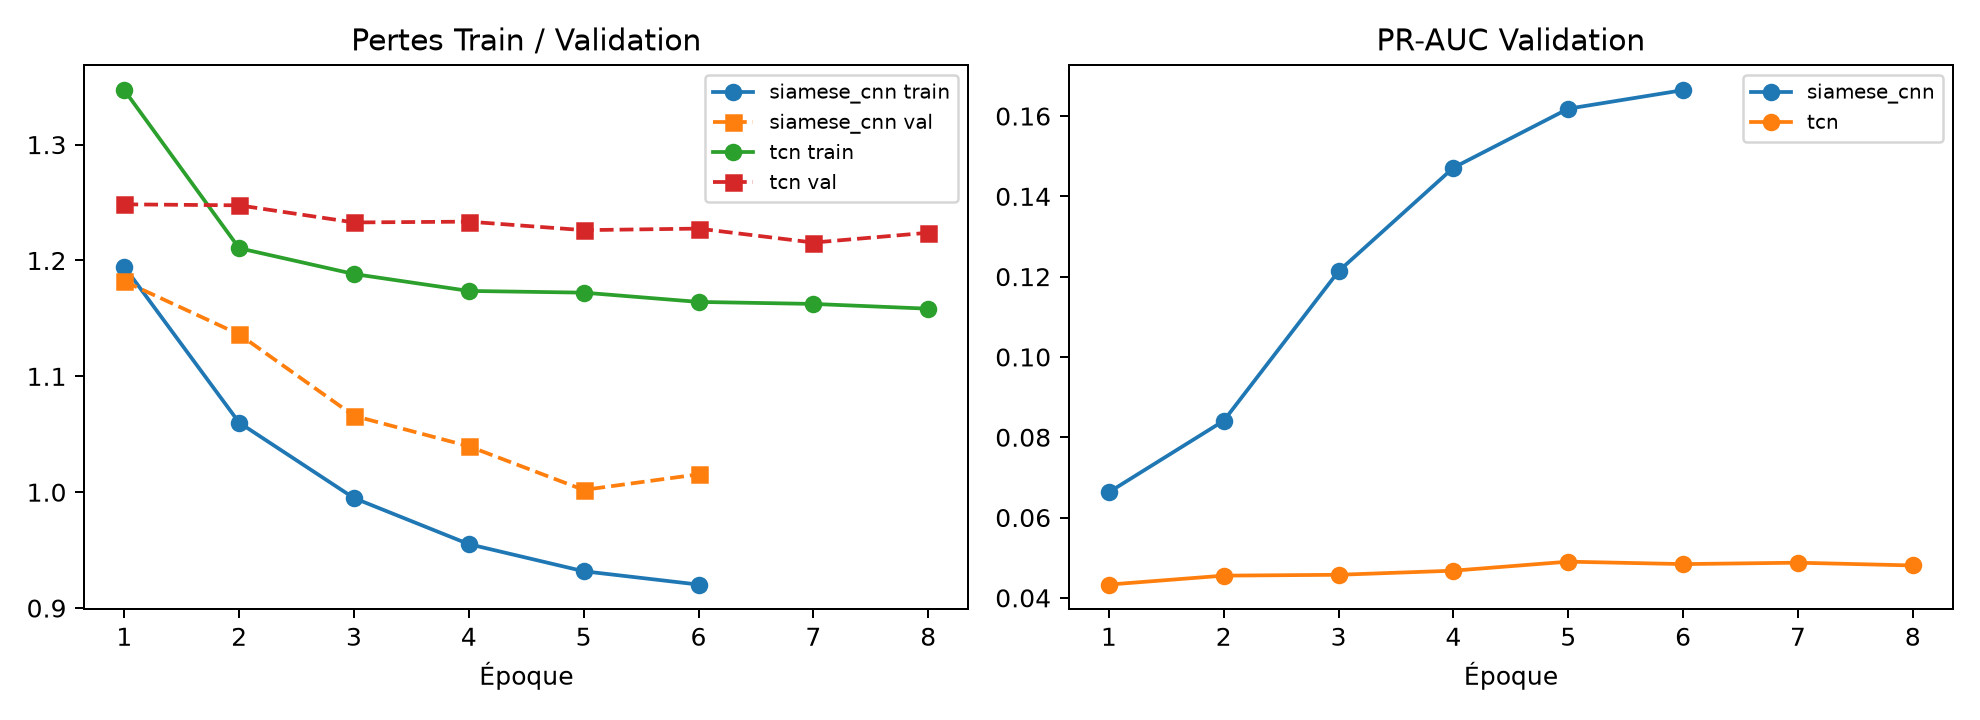

In [21]:
selected = json.loads((ROOT/'outputs/results/selected_configurations.json').read_text(encoding='utf-8'))
selected_table = pd.DataFrame([{
    'modèle': name, 'configuration': rec['config'], 'paramètres': rec['params'],
    'PR-AUC Validation': rec['pr_auc'], 'ROC-AUC Validation': rec['roc_auc'], 'seuil': rec['threshold']
} for name, rec in selected.items()]).sort_values('PR-AUC Validation', ascending=False)
display(selected_table)
display(Image(filename=str(ROOT/'outputs/figures/learning_curves_neural.png')))

## 14 — Évaluation finale sur le Test spatial figé

In [22]:
test = pd.read_csv(ROOT/'outputs/results/model_comparison_test.csv')
predictions = pd.read_csv(ROOT/'outputs/results/test_predictions_all_models.csv', dtype={'tree_id':str})
display(test)

test_ids = set(features.loc[features.split == 'test','tree_id'])
assert all(set(z.tree_id) == test_ids for _, z in predictions.groupby('model'))
print(f'Mêmes {len(test_ids)} arbres Test pour les cinq modèles ; prédictions individuelles = {len(predictions):,}.')

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,threshold,training_tuning_time_s,inference_time_s,inference_ms_per_tree
0,siamese_cnn,0.966193,0.301471,0.345992,0.322200,0.873907,0.220459,9778,190,155,82,0.881492,70.733155,0.396303,0.038834
1,tcn,0.718961,0.055424,0.691983,0.102628,0.763498,0.061736,7173,2795,73,164,0.623395,21.312441,0.056150,0.005502
2,cusum,0.913082,0.047354,0.143460,0.071204,0.652185,0.038956,9284,684,203,34,104.120000,0.056428,0.000308,0.000030
3,threshold,0.931504,0.032389,0.067511,0.043776,0.625386,0.033353,9490,478,221,16,114.120000,0.037543,0.000108,0.000011
4,isolation_forest,0.407349,0.026714,0.691983,0.051443,0.555779,0.025933,3993,5975,73,164,-0.095130,1.682710,0.177660,0.017409


Mêmes 10205 arbres Test pour les cinq modèles ; prédictions individuelles = 51,025.


Le Siamese CNN obtient la meilleure discrimination (ROC-AUC ≈ 0,874 ; PR-AUC ≈ 0,220) et le meilleur F1 (≈ 0,322). Le TCN possède un rappel élevé mais une précision très faible au seuil Validation. L'accuracy seule est trompeuse dans ce contexte : prédire presque toujours la classe normale donnerait déjà environ 97,7 %.

## 15 — Courbes ROC, précision-rappel et matrices de confusion

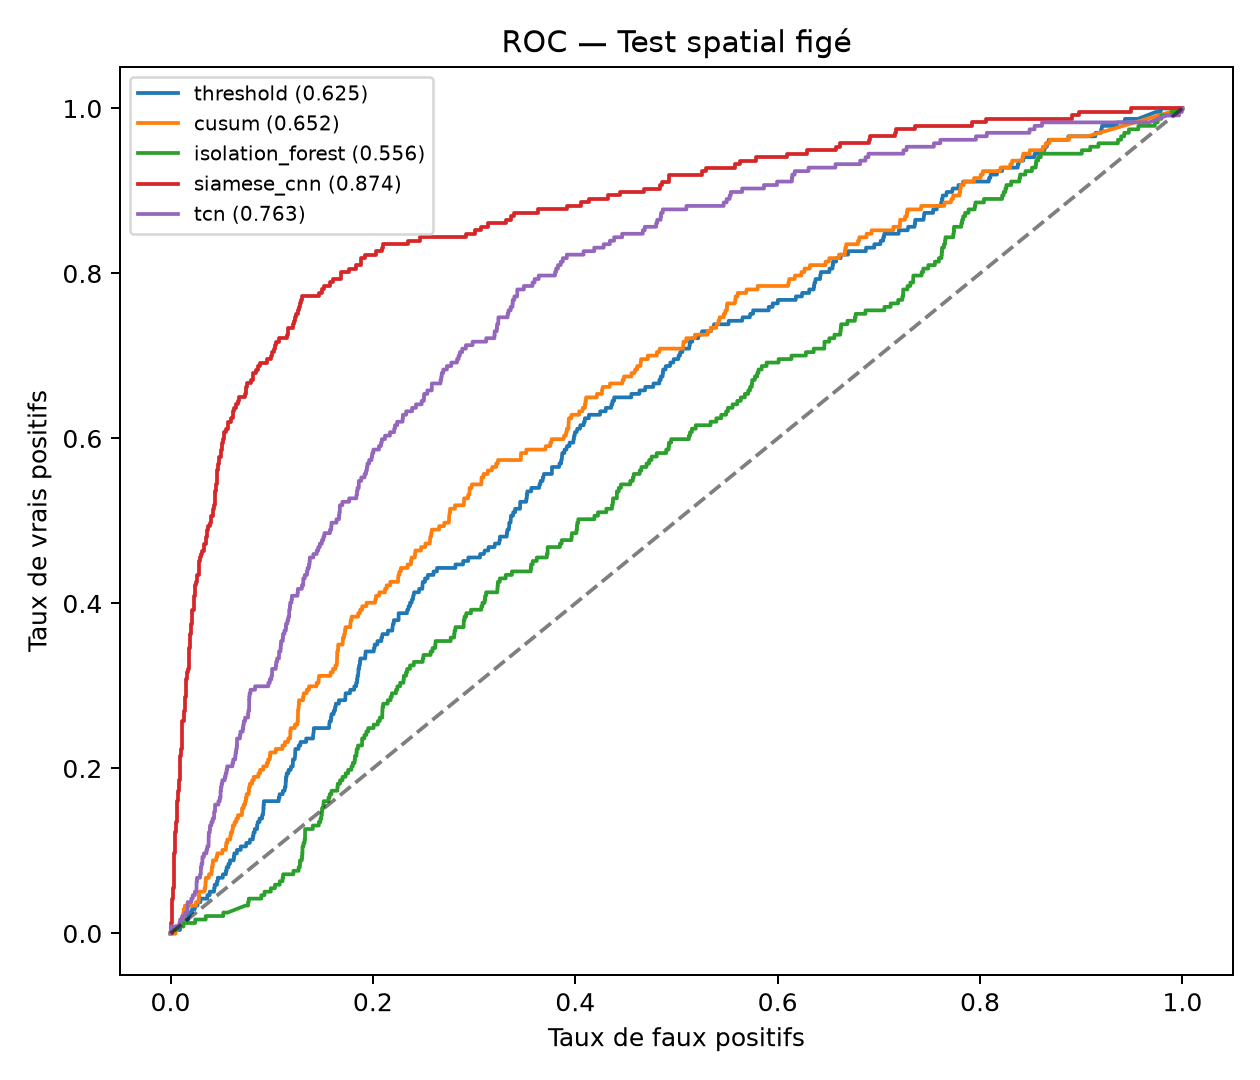

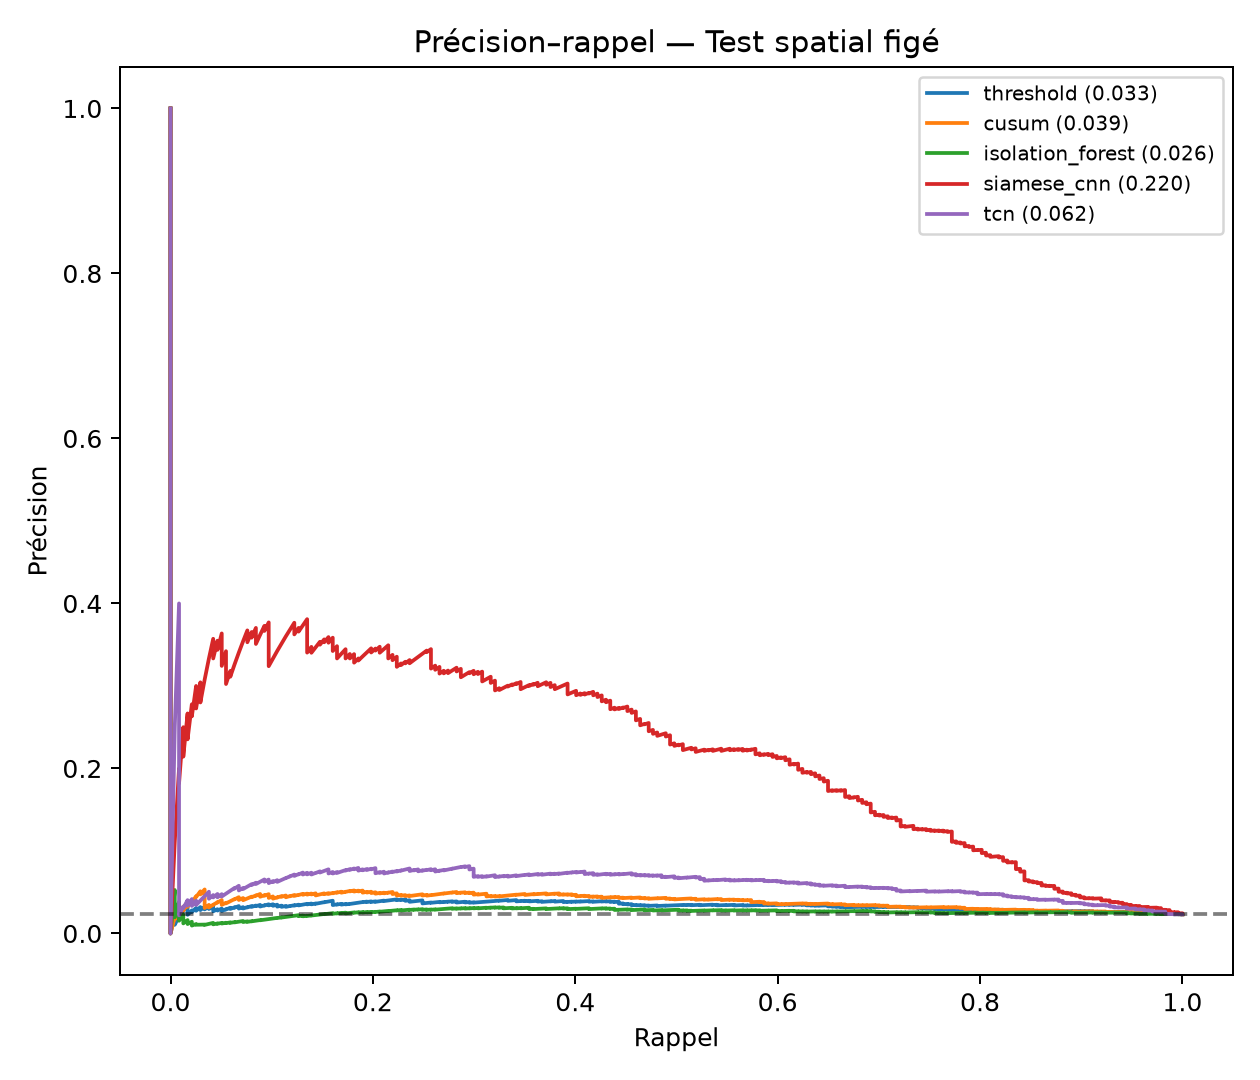

### Matrice de confusion — siamese_cnn

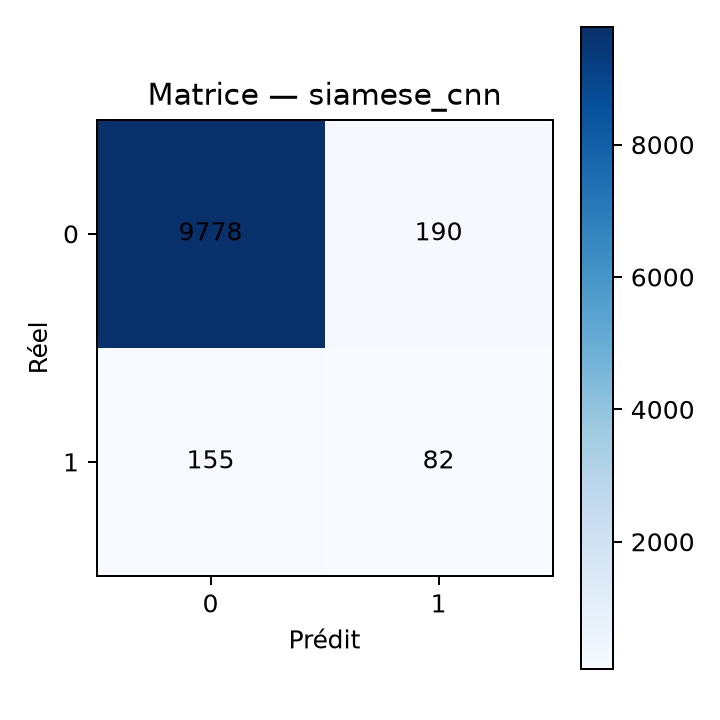

### Matrice de confusion — tcn

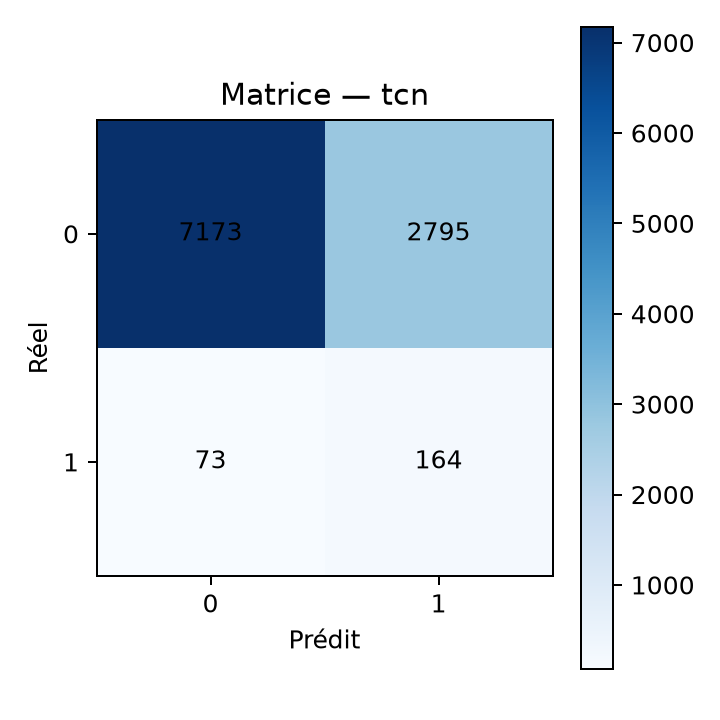

### Matrice de confusion — cusum

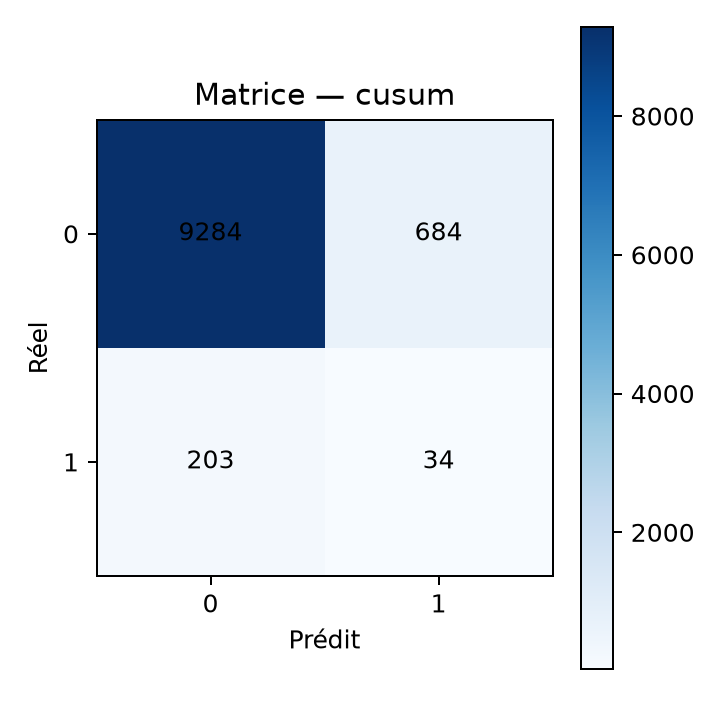

### Matrice de confusion — threshold

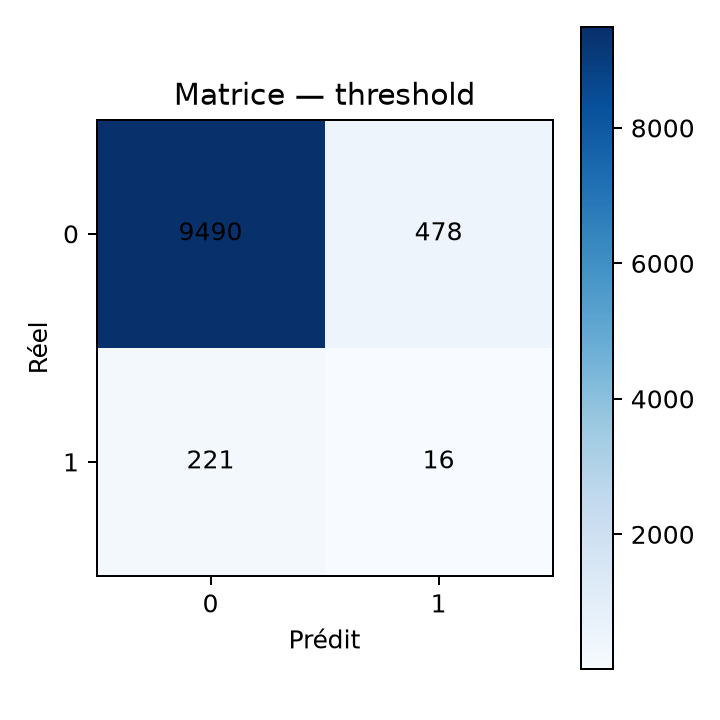

### Matrice de confusion — isolation_forest

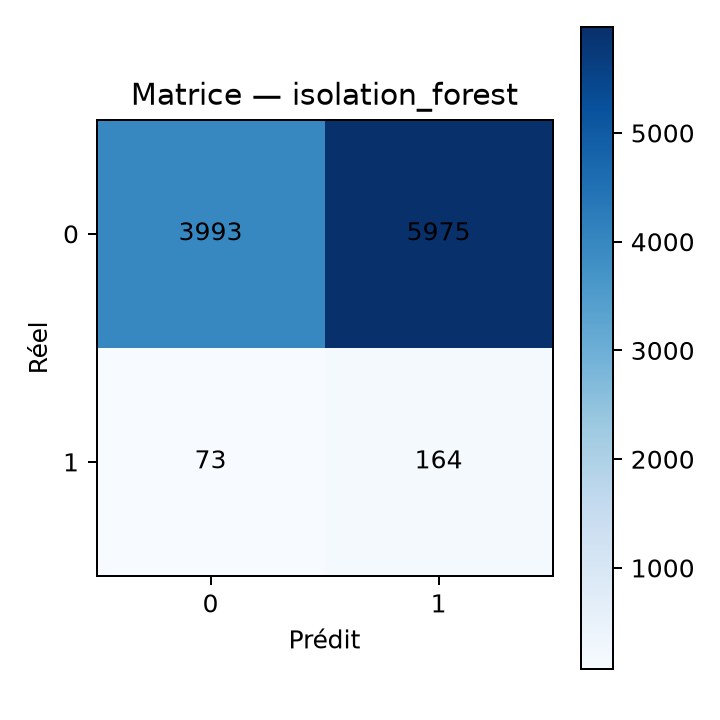

In [23]:
display(Image(filename=str(ROOT/'outputs/figures/roc_curves_test.png')))
display(Image(filename=str(ROOT/'outputs/figures/precision_recall_curves_test.png')))
for model in test.model:
    display(Markdown(f'### Matrice de confusion — {model}'))
    display(Image(filename=str(ROOT/f'outputs/figures/confusion_matrix_{model}.png')))

La courbe précision-rappel est la plus informative ici : elle tient compte de la rareté des positifs. Le Siamese conserve un avantage clair sur une partie utile de la courbe, sans que son seuil actuel rende le problème résolu.

## 16 — Analyse des erreurs et temps d'exécution

,model,errors,false_positives,false_negatives,mean_black_2021_errors,mean_black_2021_correct
0,cusum,887,684,203,0.020936,0.060455
1,isolation_forest,6048,5975,73,0.087083,0.013281
2,siamese_cnn,345,190,155,0.018580,0.058365
3,tcn,2868,2795,73,0.014659,0.073578
4,threshold,699,478,221,0.021621,0.059623


,model,training_tuning_time_s,inference_time_s,inference_ms_per_tree
3,threshold,0.037543,0.000108,0.000011
2,cusum,0.056428,0.000308,0.000030
4,isolation_forest,1.682710,0.177660,0.017409
1,tcn,21.312441,0.056150,0.005502
0,siamese_cnn,70.733155,0.396303,0.038834


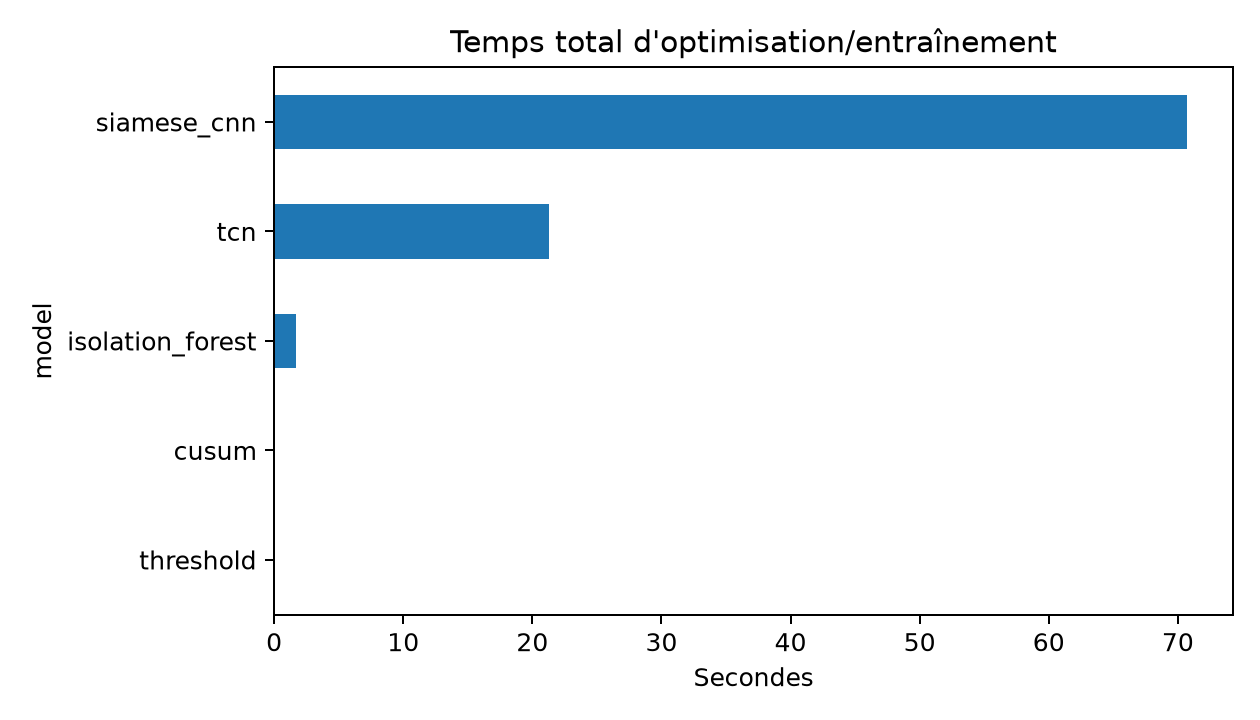

In [24]:
errors = pd.read_csv(ROOT/'outputs/results/error_analysis.csv')
display(errors)
display(test[['model','training_tuning_time_s','inference_time_s','inference_ms_per_tree']].sort_values('training_tuning_time_s'))
display(Image(filename=str(ROOT/'outputs/figures/training_times.png')))

Le Siamese est le plus coûteux à optimiser mais reste très rapide en inférence batch CPU. Les 155 faux négatifs du Test montrent qu'il ne doit pas être utilisé comme preuve phytosanitaire autonome. Le taux de pixels noirs est comparé entre erreurs et bonnes décisions, mais cette association descriptive ne démontre aucune causalité.

## 17 — Analyse post-hoc des pixels noirs du Siamese CNN

,analysis,group,black_threshold_definition,n,positives,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,original_by_black_group,none_0,0 puis médiane des valeurs non-nulles=0.242188,8232,213,0.961127,0.299625,0.375587,0.333333,0.895316,0.235796,7832,187,133,80
1,original_by_black_group,nonzero_low_le_0.242188,0 puis médiane des valeurs non-nulles=0.242188,987,11,0.987842,0.400000,0.181818,0.250000,0.895864,0.149950,973,3,9,2
2,original_by_black_group,nonzero_high_gt_0.242188,0 puis médiane des valeurs non-nulles=0.242188,986,13,0.986815,0.000000,0.000000,0.000000,0.811289,0.059127,973,0,13,0
3,sensitivity_all,original_all,alpha=0 remplacé par moyenne RGB Train; aucun ...,10205,237,0.966193,0.301471,0.345992,0.322200,0.873907,0.220459,9778,190,155,82
4,sensitivity_all,alpha0_neutralized_all,alpha=0 remplacé par moyenne RGB Train; aucun ...,10205,237,0.966193,0.301471,0.345992,0.322200,0.873756,0.220329,9778,190,155,82


black_fraction_2019        black_fraction_2021         \
                      mean median                mean median   
y_true                                                         
0                 0.057551    0.0            0.057733    0.0   
1                 0.027014    0.0            0.027014    0.0   

       black_fraction_delta_2021_minus_2019         \
                                       mean median   
y_true                                               
0                                  0.000182    0.0   
1                                  0.000000    0.0   

       invalid_alpha_fraction_2019        invalid_alpha_fraction_2021         
                              mean median                        mean median  
y_true                                                                        
0                         0.000533    0.0                    0.000533    0.0  
1                         0.000000    0.0                    0.000000    0.0

black_fraction_max                   \
                            count      mean median   
error_type                                           
correct                      9860  0.058381    0.0   
false_negative                155  0.041205    0.0   
false_positive                190  0.000123    0.0   

               invalid_alpha_fraction_2019                   \
                                     count      mean median   
error_type                                                    
correct                               9860  0.000539    0.0   
false_negative                         155  0.000000    0.0   
false_positive                         190  0.000000    0.0   

               invalid_alpha_fraction_2021                   
                                     count      mean median  
error_type                                                   
correct                               9860  0.000539    0.0  
false_negative                         155  0.000000    0.0  
false_positive                         190  0.000000    0.0

Décisions modifiées après neutralisation alpha=0 : 0
Variation absolue moyenne du score : 0.00031807409426947575


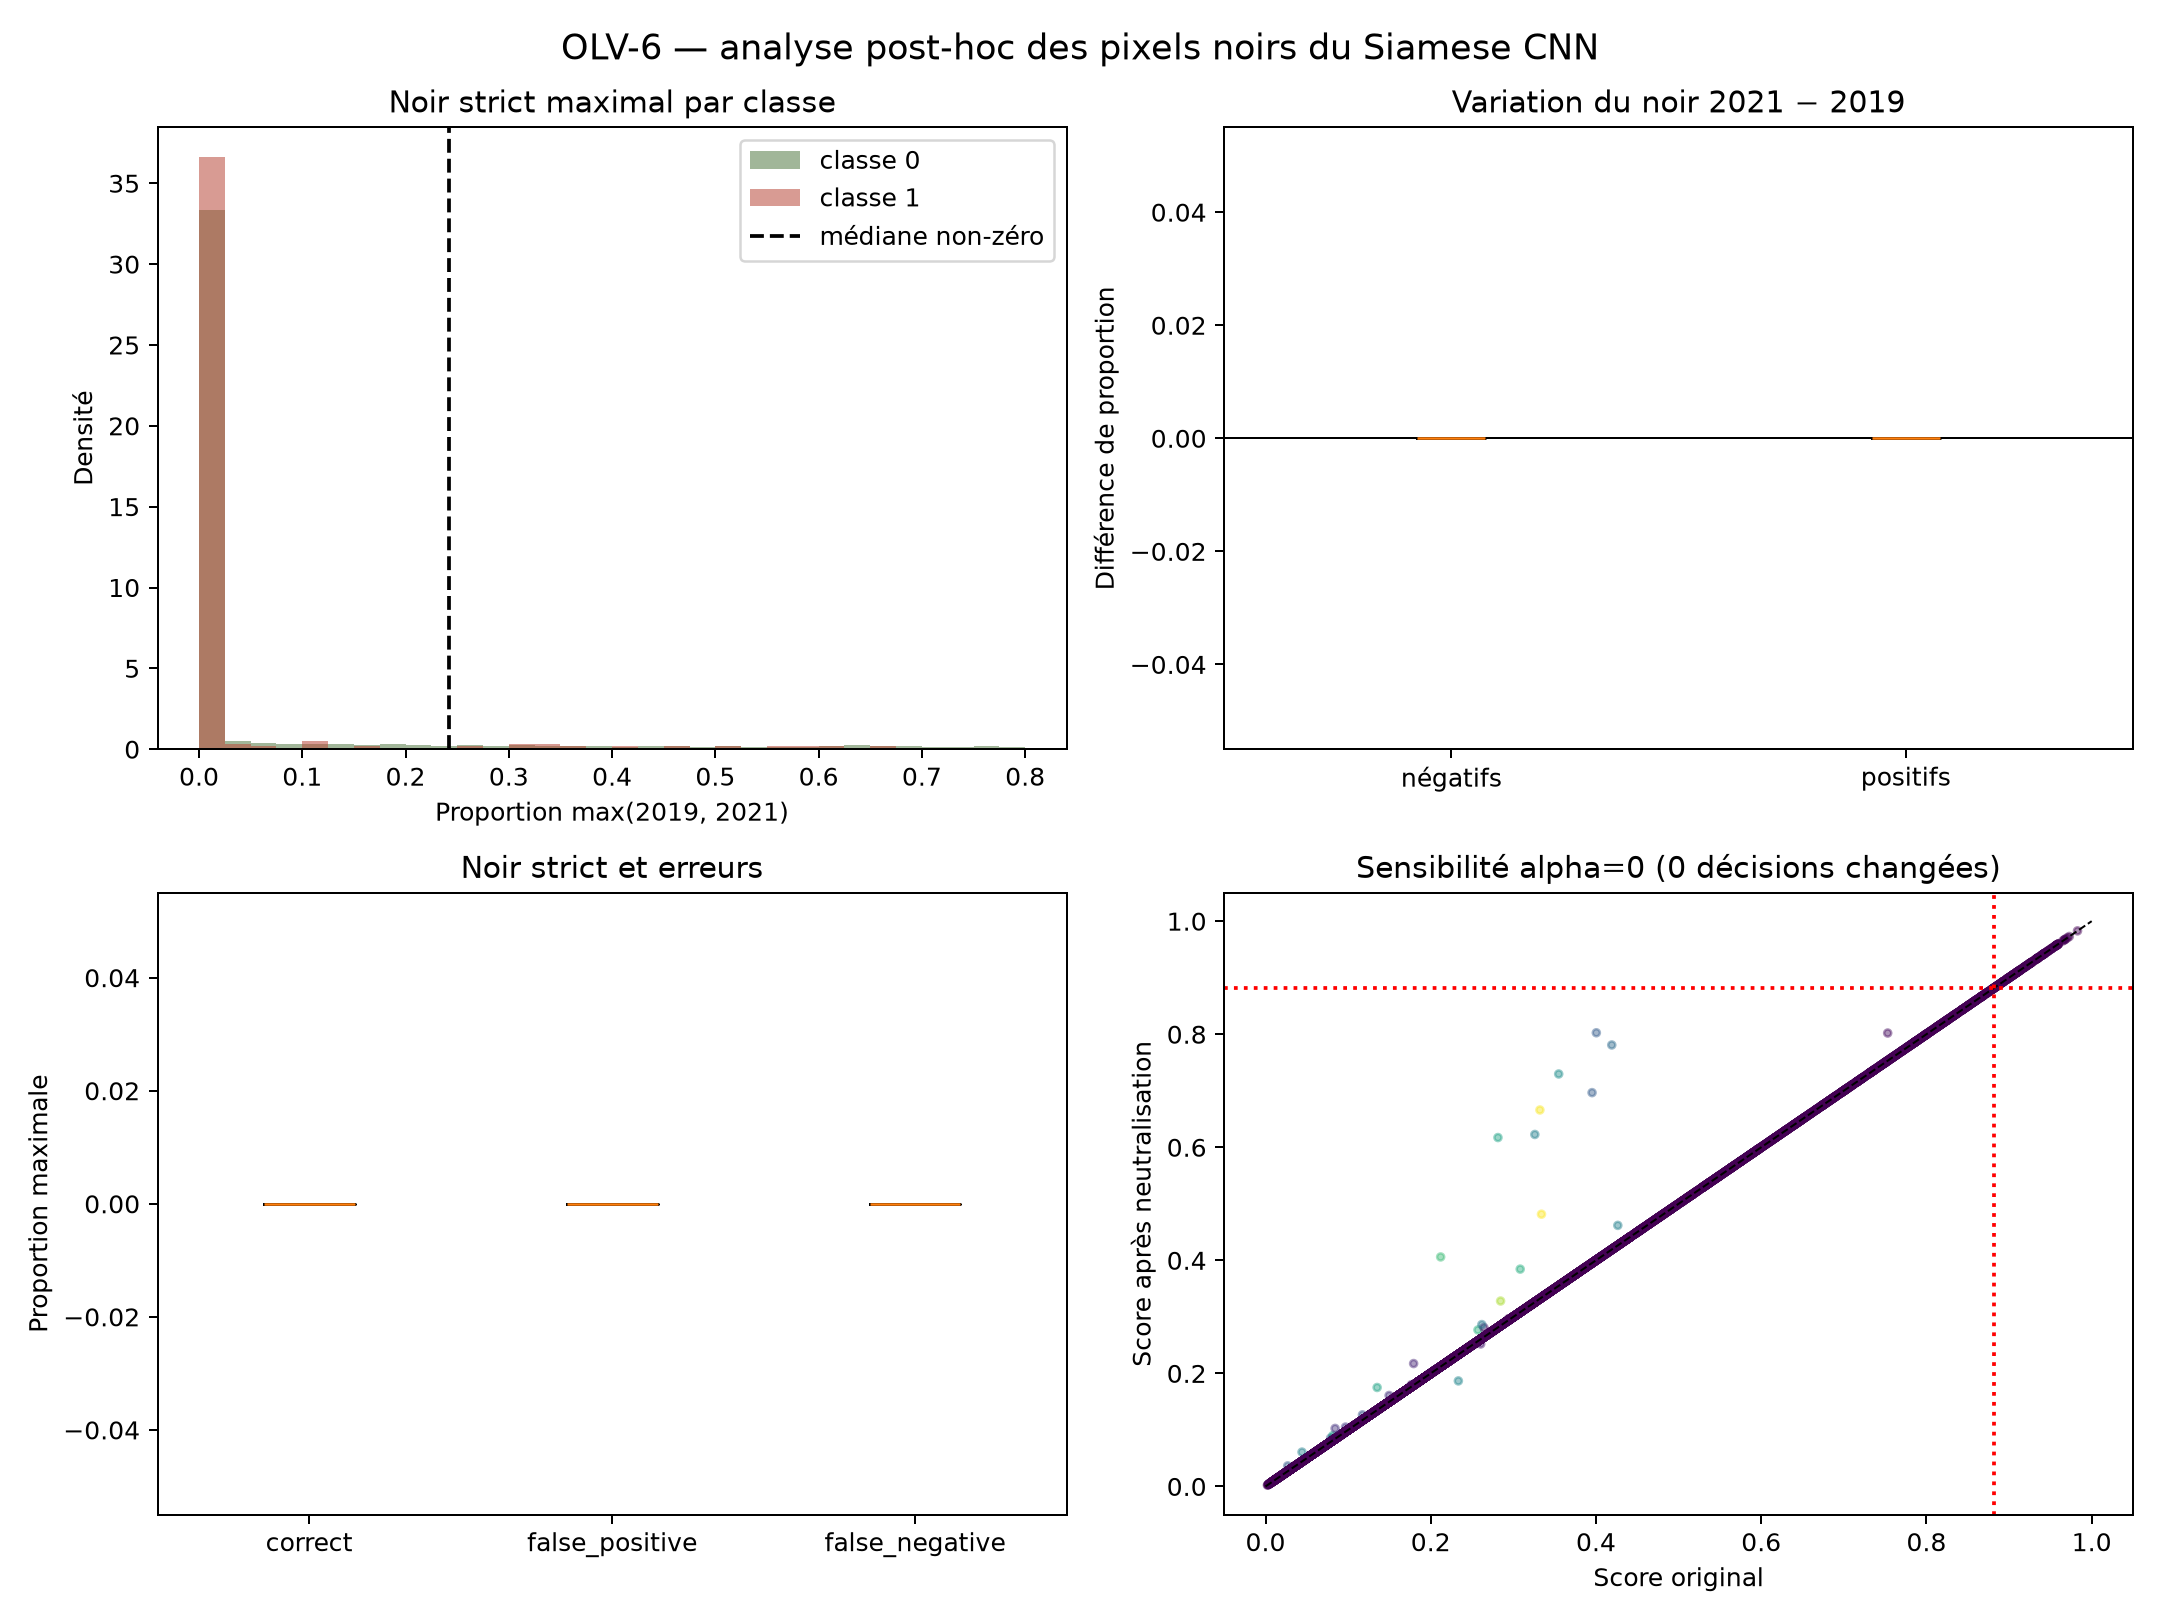

In [25]:
black = pd.read_csv(ROOT/'outputs/results/black_pixels_analysis.csv', dtype={'tree_id':str})
black_groups = pd.read_csv(ROOT/'outputs/results/black_pixels_group_metrics.csv')
display(black_groups)

label_black = black.groupby('y_true')[['black_fraction_2019','black_fraction_2021',
    'black_fraction_delta_2021_minus_2019','invalid_alpha_fraction_2019','invalid_alpha_fraction_2021']].agg(['mean','median'])
error_black = black.groupby('error_type')[['black_fraction_max','invalid_alpha_fraction_2019',
    'invalid_alpha_fraction_2021']].agg(['count','mean','median'])
display(label_black); display(error_black)
print('Décisions modifiées après neutralisation alpha=0 :', int(black.prediction_changed_after_neutralization.sum()))
print('Variation absolue moyenne du score :', black.score_change_after_neutralization.abs().mean())
display(Image(filename=str(ROOT/'outputs/figures/black_pixels_analysis.png')))

Le noir strict est défini dans la préparation par `R=G=B=0`. Cette définition mélange potentiellement nodata, bordures, ombres très profondes et véritables valeurs noires. Le canal alpha des rendus RGBA alignés fournit un proxy plus spécifique d'invalidité (`alpha=0`), mais pas un masque physique certifié.

Les groupes sont définis sans utiliser les performances : aucun noir, puis moitié basse et moitié haute des proportions non nulles (seuil médian 0,242188). Le modèle est meilleur dans le groupe sans noir et ne détecte aucun des 13 positifs du groupe le plus noir. Les faux positifs ont presque zéro noir ; les faux négatifs n'en ont pas davantage que les prédictions correctes. Neutraliser les seuls pixels `alpha=0` par la moyenne RGB Train ne modifie aucune décision. Ces observations ne soutiennent pas un raccourci simple fondé sur les pixels noirs invalides, mais elles ne prouvent pas causalement que le réseau apprend la couronne : texture du sol, ombres valides, défauts d'enregistrement et contexte spatial restent possibles.

## 18 — Contribution réelle des datasets complémentaires

In [26]:
def hyperspectral_experiment() -> dict:
    path = next((DATA / "hyperspectral").rglob("*.xlsx"))
    frame = pd.read_excel(path, sheet_name="hs_and_ground_truth")
    feature_cols = [c for c in frame.columns if str(c).startswith("_b") and str(c).endswith("_mean")]
    mask = frame.possible_inf.astype(str).str.lower().isin(["yes", "no"])
    x = frame.loc[mask, feature_cols].replace([np.inf, -np.inf], np.nan)
    y = frame.loc[mask, "possible_inf"].astype(str).str.lower().eq("yes").astype(int).to_numpy()
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
        ("pca", PCA(n_components=10, random_state=SEED)),
        ("classifier", LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000, random_state=SEED)),
    ])
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    score = cross_val_predict(pipe, x, y, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
    pred = (score >= .5).astype(int)
    out = pd.DataFrame({"id": frame.loc[mask, "id"], "y_true": y, "score_cv": score, "y_pred_0_5": pred})
    out.to_csv(RESULTS / "hyperspectral_cv_predictions.csv", index=False)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    summary = {
        "observations": len(y), "positives": int(y.sum()), "spectral_mean_features": len(feature_cols),
        "protocol": "Prédictions hors-fold, StratifiedKFold 3 plis; imputation, standardisation et PCA ajustées dans chaque pli.",
        "roc_auc_cv": float(roc_auc_score(y, score)), "pr_auc_cv": float(average_precision_score(y, score)),
        "accuracy_0_5": float(accuracy_score(y, pred)), "precision_0_5": float(precision_score(y, pred, zero_division=0)),
        "recall_0_5": float(recall_score(y, pred, zero_division=0)), "f1_0_5": float(f1_score(y, pred, zero_division=0)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "cube_linkage": "Impossible: 8 cubes sans identifiant/tag explicite contre 76 lignes agrégées; aucune correspondance n'est inventée.",
        "caution": "Seulement 6 positifs; résultat exploratoire à forte variance, non comparable au Test spatial OQDS.",
    }
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.hist(score[y == 0], bins=12, alpha=.7, label="non stressé"); ax.hist(score[y == 1], bins=6, alpha=.7, label="stress possible")
    ax.set(xlabel="Score CV hors-fold", ylabel="Effectif", title="Expérience spectrale complémentaire"); ax.legend(); fig.tight_layout(); fig.savefig(FIGURES / "hyperspectral_cv_scores.png", dpi=180); plt.close(fig)
    return summary

,NEON,Hyperspectral,CrownsDb
accuracy_0_5,NaN,0.828947,NaN
annotation_files,NaN,NaN,5084
area_change_iqr_m2,None,NaN,NaN
boxes,NaN,NaN,33479
caution,NaN,Seulement 6 positifs; résultat exploratoire à ...,NaN
cube_linkage,NaN,Impossible: 8 cubes sans identifiant/tag expli...,NaN
f1_0_5,NaN,0.235294,NaN
fn,NaN,4,NaN
fp,NaN,9,NaN
height_change_non_missing,0,NaN,NaN


,id,y_true,score_cv,y_pred_0_5
0,63,0,4.315012e-02,0
1,62,0,2.442166e-03,0
2,61,0,6.216540e-04,0
3,90,0,5.190618e-04,0
4,91,0,2.820369e-03,0
5,92,0,1.801682e-05,0
6,117,0,9.934496e-08,0
7,118,0,1.006943e-02,0
8,119,0,5.781284e-07,0
9,120,0,3.405838e-01,0


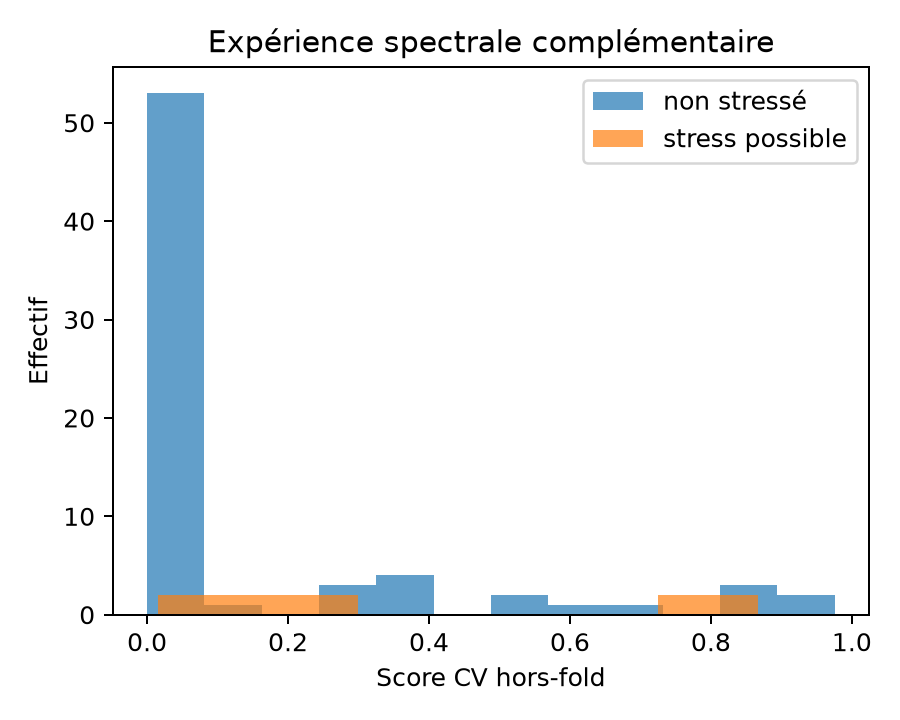

In [27]:
complementary = json.loads((ROOT/'outputs/results/complementary_experiments.json').read_text(encoding='utf-8'))
display(pd.DataFrame({k: pd.Series(v) for k,v in complementary.items()}))
display(pd.read_csv(ROOT/'outputs/results/hyperspectral_cv_predictions.csv').head(10))
display(Image(filename=str(ROOT/'outputs/figures/hyperspectral_cv_scores.png')))

- **NEON** : les identifiants répétés ont été contrôlés, mais aucune trajectoire multi-annuelle par individu n'est exploitable dans le fichier local ; aucun modèle temporel n'est annoncé.
- **Hyperspectral** : une régression logistique avec imputation, standardisation et PCA dans chaque pli produit de vraies prédictions hors-fold. Avec seulement six positifs, le résultat reste exploratoire et non comparable au Test OQDS.
- **CrownsDb** : les 33 479 boîtes ont été validées et leur échelle mesurée. Ce dataset peut soutenir une future détection/pré-segmentation de couronnes, mais pas la classification temporelle actuelle.

## 19 — Conclusion et sélection du modèle final

In [28]:
report_path = ROOT/'outputs/results/FINAL_SCIENTIFIC_REPORT.md'
display(Markdown(report_path.read_text(encoding='utf-8')))

# OliveSmart OLV-6 — comparaison scientifique de cinq algorithmes

## Objectif et données

L'expérience compare cinq pipelines sur les mêmes arbres OQDS et une séparation spatiale figée. OQDS contient trois images WorldView-2 co-enregistrées (2019–2021) et des arbres considérés infectés lorsqu'un objet présent en 2019 est absent ensuite. Cette définition est cohérente avec l'article source, mais reste une infection probable fondée sur le retrait et non un diagnostic PCR individuel ([publication OQDS](https://pmc.ncbi.nlm.nih.gov/articles/PMC12142346/)).

L'audit réel a couvert quatre sources. OQDS est seul compatible avec le benchmark temporel commun. NEON contient d'autres taxons et pas de cible OQDS; le classeur hyperspectral décrit un stress spectral très déséquilibré; CrownsDb fournit des boîtes de couronnes sans suivi sanitaire temporel.

## Préparation et protocole anti-fuite

Après retrait de 104 coordonnées dupliquées et 5026 observations invalides, 71956 arbres restent. Les six rasters OQDS partagent EPSG:32633, une résolution de 0,5 m, la même transformation et la même emprise. Les fichiers appelés NDVI sont en réalité des rendus RGBA `uint8` sans calibration; les variables correspondantes sont donc nommées intensités.

Une partition par blocs de 250 m donne Train/Validation/Test sans arbre ni bloc partagé. Toutes les transformations sont ajustées sur Train. Trois configurations sont comparées pour le seuil, Isolation Forest, Siamese et TCN; six pour CUSUM. PR-AUC Validation est le critère fixé à l'avance, adapté aux 2–3 % de positifs. Les seuils de décision sont aussi choisis sur Validation. Test n'est calculé qu'après gel des choix.

## Résultats Test

| model | accuracy | precision | recall | f1 | roc_auc | pr_auc | tn | fp | fn | tp | threshold | training_tuning_time_s | inference_time_s | inference_ms_per_tree |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| siamese_cnn | 0.9662 | 0.3015 | 0.346 | 0.3222 | 0.8739 | 0.2205 | 9778 | 190 | 155 | 82 | 0.8815 | 70.7332 | 0.3963 | 0.0388 |
| tcn | 0.719 | 0.0554 | 0.692 | 0.1026 | 0.7635 | 0.0617 | 7173 | 2795 | 73 | 164 | 0.6234 | 21.3124 | 0.0562 | 0.0055 |
| cusum | 0.9131 | 0.0474 | 0.1435 | 0.0712 | 0.6522 | 0.039 | 9284 | 684 | 203 | 34 | 104.12 | 0.0564 | 0.0003 | 0.0 |
| threshold | 0.9315 | 0.0324 | 0.0675 | 0.0438 | 0.6254 | 0.0334 | 9490 | 478 | 221 | 16 | 114.12 | 0.0375 | 0.0001 | 0.0 |
| isolation_forest | 0.4073 | 0.0267 | 0.692 | 0.0514 | 0.5558 | 0.0259 | 3993 | 5975 | 73 | 164 | -0.0951 | 1.6827 | 0.1777 | 0.0174 |

Le Siamese CNN est nettement premier: ROC-AUC 0.874, PR-AUC 0.220, F1 0.322. Il détecte 82 des 237 positifs, avec 190 faux positifs et 155 faux négatifs au seuil fixé sur Validation. Le TCN classe mieux que les méthodes simples mais son seuil Validation produit 2795 faux positifs. L'Isolation Forest est mal adaptée à cette représentation: une anomalie radiométrique n'est pas équivalente à un retrait OQDS.

Les écarts Validation/Test et les performances modestes des baselines s'expliquent notamment par la rareté et l'agrégation spatiale des cas, la radiométrie 8 bits, trois dates seulement, et le fait que le changement d'apparence n'est pas spécifique à la maladie. Les erreurs ne prouvent pas une cause unique; `error_analysis.csv` compare seulement leur proportion de pixels noirs.

## Expériences complémentaires réelles

- **NEON**: 0 individus disposent d'au moins deux années mesurables. Aucun individu n'a deux années de détection distinctes exploitables; aucun changement longitudinal n'est estimé. Les répétitions présentes ne justifient donc ni modèle temporel ni fusion avec OQDS.
- **Hyperspectral**: régression logistique après standardisation/PCA dans une CV stratifiée à trois plis, 76 observations et seulement 6 positives. PR-AUC hors-fold = 0.262; résultat exploratoire, non comparable à OQDS. Les huit cubes n'ont pas de clé permettant une correspondance fiable avec les 76 lignes.
- **CrownsDb**: 33479 boîtes vérifiées; aire relative médiane 0.0154. Usage justifié: détection/pré-entraînement de couronnes, pas classification temporelle.

## Analyse post-hoc des pixels noirs du Siamese CNN

### Protocole expérimental

L'analyse utilise exclusivement les 10 205 arbres du Test spatial figé, les patches RGB 16×16 existants, le checkpoint `siamese_cnn_best.pt` et le seuil déjà choisi sur Validation. Aucun modèle n'est réentraîné et aucun seuil n'est optimisé sur les performances Test.

Dans `prepare_oqds.py`, un pixel noir est défini strictement par `R=G=B=0`. Cette règle ne sépare pas à elle seule une zone invalide, une ombre profonde ou une valeur noire valide. Le canal `alpha=0` des rasters RGBA alignés est utilisé comme proxy plus spécifique de transparence/nodata. Il reste un masque fourni par le rendu, pas une vérité physique certifiée.

Comme 80,67 % des arbres n'ont aucun pixel noir strict dans les deux dates, les terciles ordinaires seraient dégénérés. Les groupes sont donc définis à partir de la distribution seule : (1) aucun noir ; (2) proportion non nulle inférieure ou égale à la médiane des valeurs non nulles, 0,242188 ; (3) proportion supérieure à cette médiane.

| Groupe | n | Positifs | Accuracy | Précision | Rappel | F1 | ROC-AUC | PR-AUC | TN | FP | FN | TP |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Aucun noir | 8 232 | 213 | 0,961 | 0,300 | 0,376 | 0,333 | 0,895 | 0,236 | 7 832 | 187 | 133 | 80 |
| Noir non nul ≤ 0,242188 | 987 | 11 | 0,988 | 0,400 | 0,182 | 0,250 | 0,896 | 0,150 | 973 | 3 | 9 | 2 |
| Noir non nul > 0,242188 | 986 | 13 | 0,987 | 0,000 | 0,000 | 0,000 | 0,811 | 0,059 | 973 | 0 | 13 | 0 |

Les négatifs ont en moyenne 5,76 % de noir en 2019 et 5,77 % en 2021, contre 2,70 % aux deux dates pour les positifs. La variation moyenne 2021−2019 est seulement +0,018 point de pourcentage chez les négatifs et nulle chez les positifs. La médiane est zéro dans les deux classes.

Les prédictions correctes présentent en moyenne 5,84 % de noir maximal, contre 4,12 % pour les faux négatifs et 0,012 % pour les faux positifs. Les erreurs ne présentent donc pas davantage de noir que les bonnes décisions. En particulier, les faux positifs ne sont pas associés à des patches fortement noirs.

### Test de sensibilité sans réentraînement

Seulement 34 arbres Test (0,33 %) contiennent au moins un pixel `alpha=0`. Ces pixels sont remplacés par la moyenne RGB calculée sur Train, qui correspond à une valeur normalisée neutre. Les scores originaux recalculés depuis le checkpoint reproduisent les scores sauvegardés à moins de 2×10⁻⁶.

La neutralisation ne modifie aucune des 10 205 classes prédites. La variation absolue moyenne du score est 0,000318 sur tout le Test et 0,0955 parmi les 34 arbres concernés ; la variation maximale atteint 0,402, mais reste sans franchissement du seuil de décision. ROC-AUC passe de 0,873907 à 0,873756 et PR-AUC de 0,220459 à 0,220329. Les TP, TN, FP et FN restent respectivement 82, 9 778, 190 et 155.

### Interprétation et limites

Ces résultats ne montrent pas d'indice d'un raccourci simple fondé sur les pixels noirs invalides : les performances sont maximales sans noir, les faux positifs n'en contiennent presque pas et la neutralisation `alpha=0` ne change aucune décision. En revanche, le groupe très noir contient seulement 13 positifs et aucun vrai positif, ce qui signale une faiblesse de robustesse dans ce sous-groupe.

Cette analyse n'est pas une preuve causale. La majorité des pixels noirs stricts ont `alpha>0` et peuvent correspondre à des ombres ou à des valeurs valides impossibles à distinguer avec les métadonnées disponibles. Le test ne contrôle pas les textures du sol, les variations d'illumination, les défauts de co-enregistrement ou d'autres artefacts contextuels. Une étude causale plus forte nécessiterait des masques de couronne fiables, des occlusions contrôlées et éventuellement un nouvel entraînement avec augmentation/masking explicites.

## Recommandation pour l'application JEE

Retenir le **Siamese CNN** comme moteur principal, avec un service Python d'inférence séparé exposé à JEE par REST. Le service doit recevoir deux patches RGB géoréférencés cohérents, appliquer la normalisation sauvegardée, renvoyer score, classe et version du modèle. Conserver le seuil d'intensité comme contrôle explicable/fallback, jamais comme équivalent de précision. Avant production, valider sur une nouvelle exploitation avec un test externe et, idéalement, de vrais rasters NDVI/NIR calibrés et une vérité terrain indépendante.

L'analyse des pixels noirs ne justifie pas d'abandonner le checkpoint actuel pour le prototype : aucun raccourci simple lié à `alpha=0` n'est observé. Le prétraitement doit néanmoins être renforcé avant production avec un masque explicite de validité/couronne et des contrôles d'illumination. Un prochain entraînement, autorisé séparément, devrait intégrer augmentation d'ombres/occlusions, canal de masque et validation externe afin de tester la robustesse du sous-groupe très noir.

Le TCN peut être conservé comme modèle secondaire très rapide, mais sa précision actuelle est insuffisante pour déclencher seul une alerte. Toute nouvelle région doit provoquer une validation de dérive, pas un ajustement sur le Test actuel.

## Reproductibilité et limites

Graine 20261106; Python local `.venv`; PyTorch CPU; prédictions individuelles et configurations complètes enregistrées. Les modèles neuronaux ont leurs pertes Train/Validation, ROC-AUC et PR-AUC par époque. Les limites majeures sont la cible indirecte, l'absence de NDVI physique, seulement trois dates, la dépendance spatiale résiduelle entre blocs voisins et l'extrême déséquilibre.


### Décision

Le **Siamese CNN** est retenu pour le prototype JEE, derrière un service Python REST versionné recevant deux patches RGB cohérents et retournant score, décision et version du modèle. Le seuil d'intensité reste un fallback explicable. Une validation externe sur une autre exploitation, avec vérité terrain indépendante et idéalement NIR/NDVI calibré, est indispensable avant usage opérationnel.

## 20 — Carte des fichiers nécessaires et vérification de reproductibilité

In [29]:
required_inputs = [
    'scripts/audit_datasets.py', 'scripts/prepare_oqds.py', 'scripts/train_evaluate.py',
    'scripts/complementary_report.py', 'requirements.txt',
    'data/raw/repository', 'data/neon/neon_crowns_dta.gpkg',
    'data/hyperspectral/merged_hs_olive_gr_tr.xlsx', 'data/crownsdb',
]
required_consultation = [
    'data/processed/oqds_features_splits.csv', 'outputs/results/validation_experiments.csv',
    'outputs/results/model_comparison_test.csv', 'outputs/results/test_predictions_all_models.csv',
    'outputs/results/complementary_experiments.json', 'outputs/models/siamese_cnn_best.pt',
    'outputs/models/tcn_best.pt', 'outputs/figures/roc_curves_test.png',
    'outputs/figures/precision_recall_curves_test.png', 'outputs/results/FINAL_SCIENTIFIC_REPORT.md',
]
for label, files in [('Reproduction complète', required_inputs), ('Consultation', required_consultation)]:
    missing = [p for p in files if not (ROOT/p).exists()]
    print(label, '— OK' if not missing else f'— manquants: {missing}')
    assert not missing

# Recalcul indépendant des métriques à partir des prédictions individuelles.
comparison_index = test.set_index('model')
for model, z in predictions.groupby('model'):
    recalculated = {
        'accuracy': accuracy_score(z.y_true, z.y_pred),
        'precision': precision_score(z.y_true, z.y_pred, zero_division=0),
        'recall': recall_score(z.y_true, z.y_pred, zero_division=0),
        'f1': f1_score(z.y_true, z.y_pred, zero_division=0),
        'roc_auc': roc_auc_score(z.y_true, z.score),
        'pr_auc': average_precision_score(z.y_true, z.score),
    }
    for metric_name, value in recalculated.items():
        assert np.isclose(value, comparison_index.loc[model, metric_name], atol=1e-12)

print('Vérification interne PASS : métriques recalculées, aucune fuite arbre/bloc.')
print('Le notebook courant a été exécuté en mode', EXECUTION_MODE)
display(Markdown((ROOT/'outputs/results/reproducibility_check.md').read_text(encoding='utf-8')))

Reproduction complète — OK
Consultation — OK


Vérification interne PASS : métriques recalculées, aucune fuite arbre/bloc.
Le notebook courant a été exécuté en mode consultation


# Vérification non destructive de reproductibilité OLV-6

**État : CONDITIONNELLEMENT REPRODUCTIBLE.**

Cette vérification n'a exécuté aucun `main()` scientifique et n'a entraîné aucun modèle. Elle a analysé la syntaxe, importé les modules sans lancer leurs traitements, contrôlé les dépendances, chemins, graines, partitions, configurations et empreintes des artefacts initiaux.

## Contrôles

| Contrôle | Statut | Détail |
|---|---|---|
| racine autorisée | PASS | C:\Users\Microsoft\Desktop\Project-JEE_DL |
| syntaxe audit_datasets.py | PASS | AST Python valide |
| syntaxe prepare_oqds.py | PASS | AST Python valide |
| syntaxe train_evaluate.py | PASS | AST Python valide |
| syntaxe complementary_report.py | PASS | AST Python valide |
| dépendances Python | PASS | toutes présentes |
| OQDS shapefile | PASS | chemin attendu |
| OQDS six rasters | PASS | chemin attendu |
| NEON GeoPackage | PASS | chemin attendu |
| Hyperspectral Excel | PASS | chemin attendu |
| Hyperspectral 8 cubes | PASS | chemin attendu |
| CrownsDb présent | PASS | chemin attendu |
| imports/démarrage non destructif | PASS | IMPORT_OK |
| graine préparation | PASS | 20261106 |
| graine entraînement | PASS | 20261106 |
| graine complémentaires | PASS | 20261106 |
| sélection Validation | PASS | PR-AUC et seuil sur Validation |
| Test après gel | PASS | bloc Test situé après sauvegarde des choix |
| partition arbre | PASS | {'test': 10205, 'train': 51425, 'val': 10326} |
| partition bloc spatial | PASS | {'test': 52, 'train': 258, 'val': 53} |
| folds fixés | PASS | [0, 1, 2, 3, 4, 5, 6] |
| cinq configurations sauvegardées | PASS | {'threshold': 'max_annual_decline', 'cusum': 'relative=False_k=10.0', 'isolation_forest': 'iso_2', 'siamese_cnn': 'siamese_2', 'tcn': 'tcn_0'} |
| cinq modèles/checkpoints | PASS | ['threshold.joblib', 'cusum.joblib', 'isolation_forest.joblib', 'siamese_cnn_best.pt', 'tcn_best.pt'] |
| ordre reproduction complète | PASS | audit → préparation → entraînement/évaluation → complémentaires/rapport |
| garde-fou entraînement | PASS | confirmation explicite requise |
| intégrité artefacts initiaux | PASS | {'outputs/models/threshold.joblib': True, 'outputs/models/cusum.joblib': True, 'outputs/models/isolation_forest.joblib': True, 'outputs/models/siamese_cnn_best.pt': True, 'outputs/models/tcn_best.pt': True, 'outputs/results/model_comparison_test.csv': True, 'outputs/results/test_predictions_all_models.csv': True, 'outputs/results/validation_experiments.csv': True, 'outputs/results/selected_configurations.json': True} |

## Ordre du mode complet

1. audit des quatre sources ;
2. préparation OQDS et partition spatiale ;
3. optimisation Validation, checkpoints et évaluation Test des cinq modèles ;
4. expériences complémentaires et rapport.

## Ce qui n'a pas été testé

- La reproductibilité bit-à-bit d'un nouvel entraînement PyTorch CPU/GPU.
- Le temps et la mémoire d'une nouvelle exécution intégrale.
- La stabilité des scores sur une seconde graine ou un autre matériel.
- La réussite de chaque écriture au terme d'un run complet interrompu/repris.

## Point de sécurité important

Les scripts actuels utilisent des chemins de sortie fixes. Une véritable `reproduction_complete` dans ce même dossier remplacerait notamment :
- `data/processed/oqds_features_splits.csv`
- `outputs/results/model_comparison_test.csv`
- `outputs/results/test_predictions_all_models.csv`
- `outputs/models/siamese_cnn_best.pt`
- `outputs/models/tcn_best.pt`

Elle ne doit donc pas être lancée tant que les résultats initiaux doivent rester intacts. Pour une preuve complète, il faut exécuter dans une copie isolée du projet ou ajouter un identifiant de run (`outputs/runs/<run_id>/` et `data/processed/runs/<run_id>/`), puis comparer les métriques et empreintes.

## Conclusion

Les contrôles structurels passent et le pipeline est cohérent avec le protocole annoncé. La reproductibilité scientifique complète reste à démontrer par une réexécution isolée autorisée; elle n'est pas équivalente au présent contrôle non destructif.


En mode consultation, les métriques sont relues depuis les prédictions sauvegardées et les contrôles de fuite sont recalculés, mais aucun poids n'est réoptimisé. En reproduction complète, les quatre scripts repartent des données brutes dans l'ordre scientifique et recréent les artefacts. Le manifeste `outputs/results/artifact_manifest.csv` fournit les empreintes SHA-256 des livrables contrôlés.